In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

In [2]:
os.makedirs('videos', exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
    dest = os.path.join('videos', filename)
    os.rename(filename, dest)
    print(f"File '{filename}' Moved To '{dest}'.")

print("\nContents Of Videos Folder:")
print(os.listdir('videos'))

Saving slow_traffic_small.mp4 to slow_traffic_small.mp4
File 'slow_traffic_small.mp4' Moved To 'videos/slow_traffic_small.mp4'.

Contents Of Videos Folder:
['slow_traffic_small.mp4']


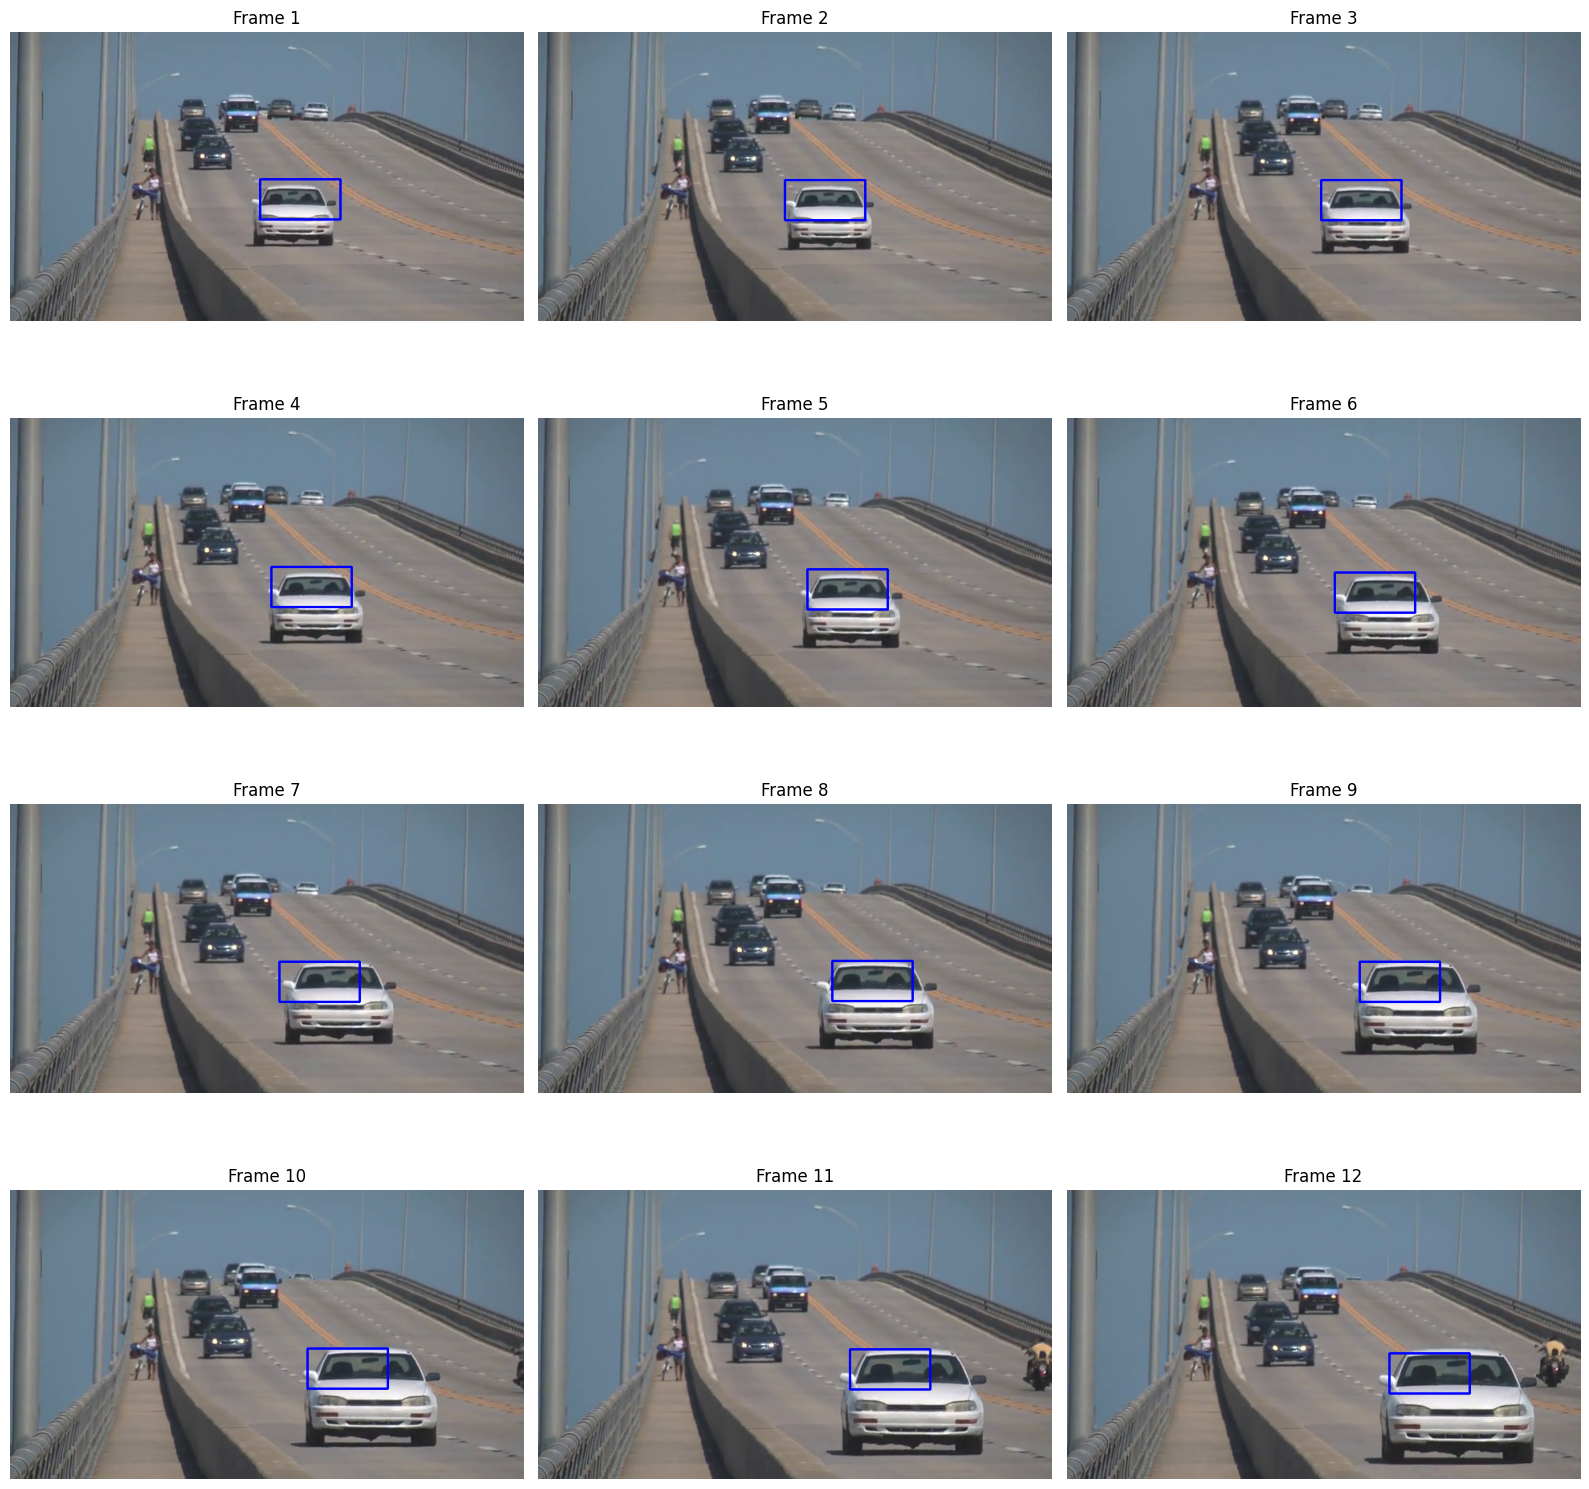

In [5]:
video_files = [f for f in os.listdir('videos') if f.lower().endswith(('.avi', '.mp4', '.mov', '.mkv'))]
if not video_files:
  raise ValueError("No Video Files Found In The 'videos' Folder.")

video_path = os.path.join('videos', video_files[0])

cap = cv2.VideoCapture(video_path)
ret, frame = cap.read()
x, y, w, h = 300, 200, 100, 50
track_window = (x, y, w, h)
roi = frame[y:y+h, x:x+w]
hsv_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)
mask = cv2.inRange(hsv_roi, np.array((0., 60., 32.)), np.array((180., 255., 255.)))
roi_hist = cv2.calcHist([hsv_roi], [0], mask, [180], [0, 180])
cv2.normalize(roi_hist, roi_hist, 0, 255, cv2.NORM_MINMAX)
term_crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 1)

frames_to_show = []
max_frames = 12
frame_idx = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    dst = cv2.calcBackProject([hsv], [0], roi_hist, [0, 180], 1)
    ret, track_window = cv2.meanShift(dst, track_window, term_crit)
    x, y, w, h = track_window
    img2 = cv2.rectangle(frame, (x, y), (x+w, y+h), 255, 2)

    frame_idx += 1
    if frame_idx % 10 == 0 and len(frames_to_show) < max_frames:
        frames_to_show.append(img2.copy())

cap.release()

n = len(frames_to_show)

plt.figure(figsize=(16, 4 * ((n + 2) // 3)))

for i in range(n):
    plt.subplot((n + 2) // 3, 3, i + 1)
    plt.imshow(frames_to_show[i][..., ::-1])
    plt.title(f"Frame {i + 1}")
    plt.axis('off')

plt.tight_layout()
plt.show()

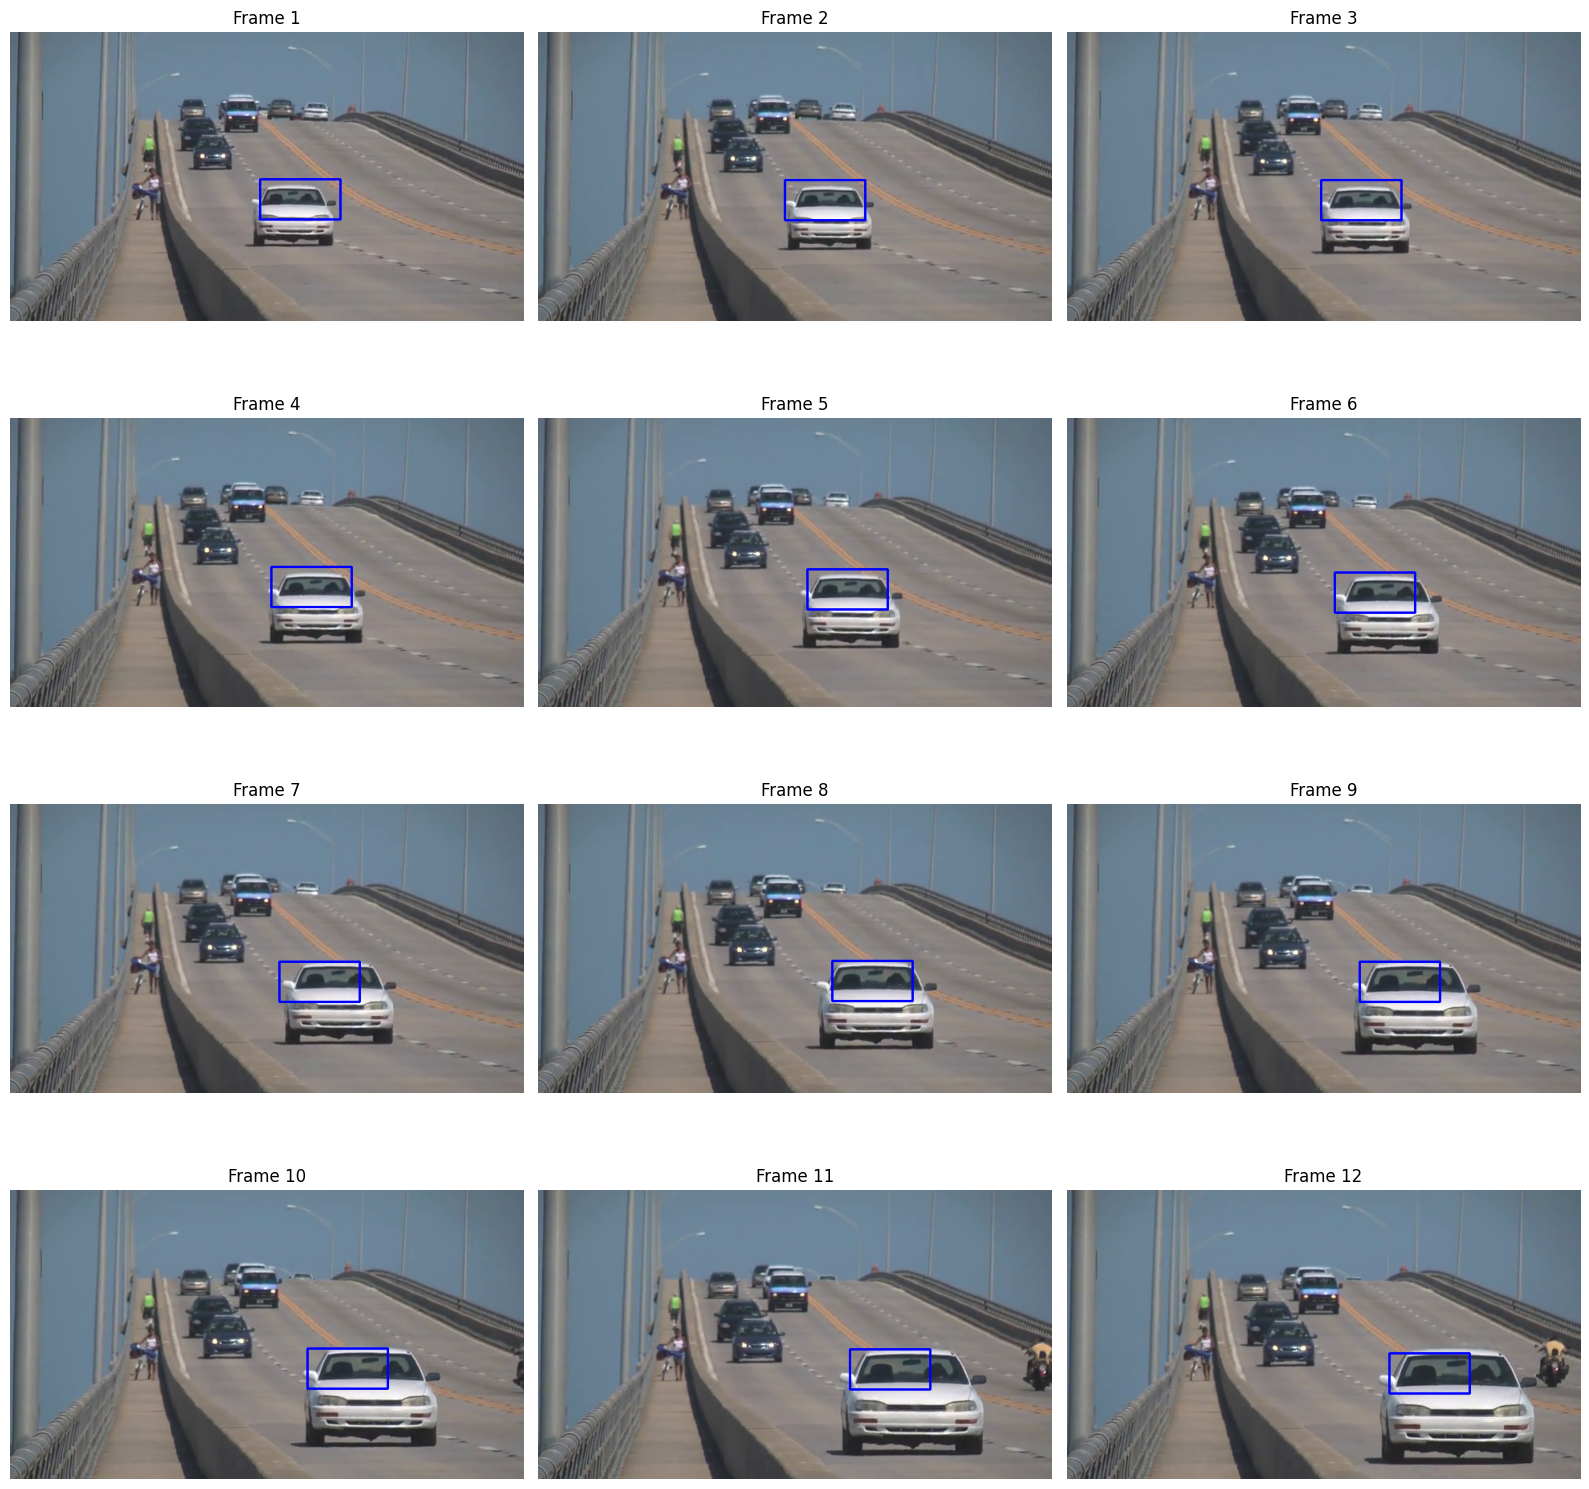

In [7]:
cap = cv2.VideoCapture(video_path)

ret, frame = cap.read()
x, y, w, h = 300, 200, 100, 50
track_window = (x, y, w, h)
roi = frame[y:y+h, x:x+w]
hsv_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)
mask = cv2.inRange(hsv_roi, np.array((0., 60., 32.)), np.array((180., 255., 255.)))
roi_hist = cv2.calcHist([hsv_roi], [0], mask, [180], [0, 180])
cv2.normalize(roi_hist, roi_hist, 0, 255, cv2.NORM_MINMAX)
term_crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 1)

frames_to_show = []
max_frames = 12
frame_idx = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    dst = cv2.calcBackProject([hsv], [0], roi_hist, [0, 180], 1)
    ret, track_window = cv2.meanShift(dst, track_window, term_crit)

    x, y, w, h = track_window
    img2 = cv2.rectangle(frame, (x, y), (x+w, y+h), 255, 2)

    frame_idx += 1
    if frame_idx % 10 == 0 and len(frames_to_show) < max_frames:
        frames_to_show.append(img2.copy())

cap.release()

n = len(frames_to_show)

plt.figure(figsize=(16, 4 * ((n + 2) // 3)))

for i in range(n):
    plt.subplot((n + 2) // 3, 3, i + 1)
    plt.imshow(frames_to_show[i][..., ::-1])
    plt.title(f"Frame {i + 1}")
    plt.axis('off')

plt.tight_layout()
plt.show()